# Chapter 08: Model Comparison as Code Efficiency — Cross-Entropy, WAIC & PSIS-LOO

> *"Everything should be made as simple as possible, but not simpler."*  
> — Albert Einstein

In Chapter 07, we saw how hierarchical modeling compresses test fleet flakiness, balancing individual noise against fleet-wide stability via the Information Bottleneck.

Now suppose your machine learning or reliability engineering team builds three competing statistical models to predict whether a pull request build will fail due to test flakiness:
1. **Model 1 (Flat Bernoulli)**: A single global flakiness rate $\theta_{\text{fleet}}$.
2. **Model 2 (Hierarchical by Service)**: Partial pooling across microservices with random intercepts.
3. **Model 3 (Massive Feature Interaction Model)**: 45 covariates including commit author, lines of code changed, time of day, CI runner host ID, git branch name, and CPU cache misses.

On historical training data, Model 3 achieves an astonishing 99.4% accuracy, predicting past test outcomes almost without flaw. Model 1 achieves 81%, and Model 2 achieves 89%.

Should you deploy Model 3 to your production CI infrastructure?

If you do, your CI budget will likely explode and your false positive rate will surge. Model 3 has memorized the idiosyncratic noise of past runs—it is catastrophically overfitted.

How do we scientifically compare models and penalize complexity without guessing?
- In **Information Theory**, the answer is **Minimum Description Length (MDL) and Cross-Entropy**: the best model compresses unseen out-of-sample test results into the shortest binary code.
- In **Bayesian Statistics**, the answer is **Out-of-Sample Predictive Density via WAIC and PSIS-LOO**: estimating generalization error while using the variance of posterior surprise to diagnose overconfidence.

This chapter unifies Bayesian model comparison with information-theoretic compression.


## 1. Out-of-Sample Predictive Density as Compression

When Claude Shannon established information theory in 1948, he proved that the optimal code length to transmit a sequence of symbols drawn from true distribution $p(y)$ using model distribution $q(y)$ is the cross-entropy:
$$H(p, q) = -\mathbb{E}_{p}[\log_2 q(y)] = H(p) + D_{\text{KL}}(p \parallel q)$$

In Bayesian statistics, when we evaluate a model $\mathcal{M}$ parameterized by $\boldsymbol{\theta}$ with posterior $p(\boldsymbol{\theta} \mid \mathcal{D}_{\text{train}})$, the predictive distribution for a new, unseen build outcome $\tilde{y}$ is:
$$p(\tilde{y} \mid \mathcal{D}_{\text{train}}) = \int p(\tilde{y} \mid \boldsymbol{\theta}) p(\boldsymbol{\theta} \mid \mathcal{D}_{\text{train}}) d\boldsymbol{\theta}$$

The **Expected Log Pointwise Predictive Density (elpd)** measures the average log probability our model assigns to unseen out-of-sample data points $\tilde{y}_i$:
$$\text{elpd} = \sum_{i=1}^n \mathbb{E}_{f}[\ln p(\tilde{y}_i \mid \mathcal{D}_{\text{train}})]$$

Notice the exact identity:
$$\text{elpd} = - n \ln(2) \cdot H(f, p_{\text{post}})$$

**Maximizing out-of-sample Bayesian predictive accuracy is mathematically identical to minimizing out-of-sample transmission code length.** 
A model that overfits to training data allocates code words to historical noise, leaving long, inefficient code words for future builds.


## 2. WAIC: Penalizing the Variance of Surprise

Calculating true out-of-sample predictive density requires infinite unseen test runs. In practice, we only have our training set of $n$ observed test results $y_1, \dots, y_n$.

If we evaluate log-predictive density on the training data directly, we get the **Log Pointwise Predictive Density (lppd)**:
$$\text{lppd} = \sum_{i=1}^n \ln \left( \frac{1}{S} \sum_{s=1}^S p(y_i \mid \boldsymbol{\theta}^{(s)}) \right)$$
where $S$ is the number of MCMC posterior draws.

The training $\text{lppd}$ is always overly optimistic because the parameters were tuned to fit those exact $y_i$. How much optimism penalty must we subtract?

Akihiro Watanabe (2010) derived the **Widely Applicable Information Criterion (WAIC)**, which computes the effective number of parameters $p_{\text{WAIC}}$ directly from the posterior distribution:
$$p_{\text{WAIC}} = \sum_{i=1}^n \text{Var}_{\text{post}}\left(\ln p(y_i \mid \boldsymbol{\theta})\right)$$

Look closely at this formula through the lens of information theory:
- $\ln p(y_i \mid \boldsymbol{\theta})$ is the **self-information (surprise)** of datum $y_i$ under parameter draw $\boldsymbol{\theta}$.
- $\text{Var}_{\text{post}}(\ln p(y_i \mid \boldsymbol{\theta}))$ is the **variance of surprise** across the posterior distribution!

If a parameter vector is tightly constrained by the data, every posterior sample $\boldsymbol{\theta}^{(s)}$ assigns approximately the same probability to $y_i$, so the variance of surprise is near zero.
If a model is overly complex and flexible, different posterior draws disagree wildly on how to explain $y_i$, causing the variance of surprise to explode!

The WAIC metric on deviance scale (multiplying by $-2$) is:
$$\text{WAIC} = -2 \left( \text{lppd} - p_{\text{WAIC}} \right)$$

Lower WAIC indicates shorter expected code length on unseen future builds.


## 3. PSIS-LOO: Exact Leave-One-Out Cross-Validation Without Re-Fitting

The gold standard for out-of-sample validation is **Leave-One-Out Cross-Validation (LOO-CV)**: fit the model on $n-1$ data points, and compute the log-likelihood of the single held-out point $y_i$, repeating for all $i=1, \dots, n$:
$$\text{elpd}_{\text{loo}} = \sum_{i=1}^n \ln p(y_i \mid \mathcal{D}_{-i})$$

In production, running full MCMC $n$ separate times (where $n = 50,000$ test builds) would cost thousands of GPU hours.

### Importance Sampling to the Rescue
We can estimate $p(y_i \mid \mathcal{D}_{-i})$ using posterior draws from the full-data model $p(\boldsymbol{\theta} \mid \mathcal{D})$ by reweighting with importance weights:
$$r_i^{(s)} = \frac{p(\boldsymbol{\theta}^{(s)} \mid \mathcal{D}_{-i})}{p(\boldsymbol{\theta}^{(s)} \mid \mathcal{D})} \propto \frac{1}{p(y_i \mid \boldsymbol{\theta}^{(s)})}$$

The importance weight is simply the inverse likelihood of datum $y_i$!
If a datum is highly surprising to the model ($p(y_i \mid \boldsymbol{\theta})$ is tiny), its importance weight $r_i$ explodes to infinity, causing importance sampling variance to become infinite.

### Pareto Smoothing (Vehtari, Gelman, Gabry 2017)
To stabilize heavy-tailed importance ratios, Vehtari et al. fit a **Generalized Pareto Distribution (GPD)** to the upper $20\%$ largest weights $r_i^{(s)}$:
$$F(r) = 1 - \left(1 + \frac{k(r - \mu)}{\sigma}\right)^{-1/k}$$

The shape parameter $k$ is the famous **Pareto $k$ diagnostic**:
- **$k < 0.5$**: The importance distribution has finite variance; LOO estimates converge rapidly.
- **$0.5 \le k < 0.7$**: Slower convergence, but still practically reliable.
- **$k \ge 0.7$**: The distribution has infinite variance! The importance weights are unstable; datum $y_i$ is an extreme high-leverage outlier that exerts excessive pull on the posterior.

```
       Pareto k Diagnostic Gauge:
       [==== Safe (k < 0.5) ====][== Caution (0.5 <= k < 0.7) ==][==== DANGER (k >= 0.7) ====]
       Finite Variance          Slow Convergence                 Infinite Variance (Outlier)
       LOO-CV Highly Reliable   Acceptable                       Datum exerts excessive leverage
```


## 4. Minimum Description Length and Bayesian Model Stacking

When comparing multiple candidate models $\mathcal{M}_1, \mathcal{M}_2, \dots, \mathcal{M}_M$, we compute their difference in predictive performance:
$$\Delta \text{elpd}_{12} = \text{elpd}_{\text{loo}}^{(1)} - \text{elpd}_{\text{loo}}^{(2)}$$
along with the standard error of the difference:
$$\text{SE}(\Delta \text{elpd}) = \sqrt{n \cdot \text{Var}_i \left( \text{elpd}_{\text{loo}, i}^{(1)} - \text{elpd}_{\text{loo}, i}^{(2)} \right)}$$

A model is definitively superior only if:
$$\Delta \text{elpd} > 2 \times \text{SE}(\Delta \text{elpd})$$

### Model Stacking (Optimal Ensemble Compression)
Rather than picking a single "winning" model (which discards complementary information), we can combine all $M$ models with weights $\mathbf{w} = (w_1, \dots, w_M)^T$ by solving a strictly concave log-score maximization:
$$\max_{\mathbf{w} \in \Delta^M} \sum_{i=1}^n \ln \left( \sum_{m=1}^M w_m p(y_i \mid \mathcal{D}_{-i}, \mathcal{M}_m) \right)$$

This is equivalent to constructing a **multi-code mixture compressor** that achieves optimal cross-entropy by hedging across models.


## 5. What Do We Actually Do With This Number? (From Wasted Bits to Operational Action)

Every theoretical diagnostic in this chapter maps directly to software and CI decisions.

### Action 1: Automated Gating for ML/CI Models
- **The Problem**: A data scientist submits a PR adding a new Transformer-based flakiness predictor. It claims $99\%$ training accuracy.
- **The Operational Rule**: Compute $\Delta \text{elpd}_{\text{loo}}$ against the production baseline.
  - If $\Delta \text{elpd}_{\text{loo}} \le 2 \times \text{SE}$, **reject the PR**. The model's complexity is not justified by out-of-sample data compression.
  - If $\Delta \text{elpd}_{\text{loo}} > 2 \times \text{SE}$, **approve for shadow deployment**.

### Action 2: Triaging Outliers via Pareto $k \ge 0.7$
- **The Problem**: CI pipelines occasionally experience catastrophic anomalous failures (e.g., Jenkins worker ran out of disk space, or network switch dropped packets). These "black swans" poison regular flaky test models.
- **The Operational Rule**: Filter the dataset using the Pareto diagnostic:
  - If a failed test run $y_i$ has Pareto $k_i \ge 0.7$, **it is an environmental outlier, not code flakiness**.
  - Automatically tag the run as an *Infrastructure Outlier*, isolate it from test flakiness scorecards, and route the incident to SRE/DevOps rather than the developer who authored the commit.

### Action 3: Log Compression and Cloud Compute Sizing
- **The Problem**: Storing raw CI execution traces for 100,000 builds per day costs thousands of dollars per month in S3/BigQuery.
- **The Operational Rule**: Convert cross-entropy differences $\Delta H$ directly to storage dollars:
  $$\text{Storage Savings (GB/year)} = \frac{\Delta H \text{ (bits/build)} \times 100,000 \text{ builds/day} \times 365}{8 \times 10^9}$$
  A model that achieves 0.8 bits/build cross-entropy reduction over naive Bernoulli encoding saves gigabytes of log payload daily when compressing test telemetry.


## 6. Summary and Roadmap

| Concept | Information Theory View | Bayesian Statistics View | Operational CI Action |
| :--- | :--- | :--- | :--- |
| **Out-of-sample accuracy** | Minimal cross-entropy $H(p, q)$ code length | Maximal $\text{elpd}_{\text{loo}}$ predictive density | Predict build failure on future PRs |
| **Model complexity penalty** | Description length of parameters $L(\mathcal{M})$ | Variance of surprise $p_{\text{WAIC}} = \sum \text{Var}(\ln p)$ | Reject overparameterized 45-feature models |
| **Pareto $k$ diagnostic** | Code word length variance / infinite moment | Posterior leverage / outlier influence | Route infrastructure crashes away from devs |
| **Model Stacking** | Mixture codebook with optimal bit allocation | Cross-validation weight optimization | Combine static analysis with dynamic flakiness |

In the next chapter (**Chapter 09: To Merge or Re-Run? — Bayesian Decisions & Wald SPRT**), we will turn these predictive models into active operational decisions: *Given our current posterior and risk thresholds, should we merge the PR, fail the build, or run one more test retry?*


## 7. Python Implementation: WAIC, PSIS-LOO, and Pareto $k$ Diagnostics

Let us implement:
1. Three competing models on synthetic flaky test data:
   - **Model 1 (Flat Pooling)**: Single fleet rate $\theta$.
   - **Model 2 (Hierarchical / Service Pooling)**: Microservice-level partial pooling.
   - **Model 3 (Overparameterized Covariates)**: High-degree polynomial feature expansion that overfits to training data.
2. Exact calculation of Log Pointwise Predictive Density ($\text{lppd}$) and $p_{\text{WAIC}}$.
3. PSIS-LOO implementation with Generalized Pareto tail fitting to calculate Pareto $k$ diagnostics.
4. Model comparison table with $\Delta \text{elpd}$, $\text{SE}$, and stacking weights.
5. 3-tier exercises with solutions.


In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(42)

# Set publication style
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 16,
    'figure.dpi': 120
})


In [2]:
# -------------------------------------------------------------
# 1. Generate Synthetic CI Flakiness Data with Genuine Structure + Outliers
# -------------------------------------------------------------
N_builds = 250
# True generative process: 3 services, flakiness depends on code churn (x) + service intercept
service_ids = np.random.choice([0, 1, 2], size=N_builds, p=[0.4, 0.4, 0.2])
service_intercepts = np.array([-3.0, -1.8, -4.0]) # Auth, Payment, Search
churn = np.random.exponential(scale=1.5, size=N_builds) # Normalized churn in hundreds of lines

true_latent = service_intercepts[service_ids] + 0.45 * churn
true_prob = 1.0 / (1.0 + np.exp(-true_latent))

# Observed binary outcomes (1 = flakiness failure, 0 = success)
y_obs = np.random.binomial(1, true_prob)

# Inject 3 severe infrastructure black-swan outliers (unrelated to churn, runner killed)
outlier_indices = [15, 88, 192]
y_obs[outlier_indices] = 1
churn[outlier_indices] = 0.05 # tiny churn, but crashed due to OOM!

print(f"Observed Builds: {N_builds}")
print(f"Total Failures: {np.sum(y_obs)} ({np.mean(y_obs)*100:.1f}%)")
print(f"Service Breakdown: {np.bincount(service_ids)}")


Observed Builds: 250
Total Failures: 36 (14.4%)
Service Breakdown: [110  87  53]


In [3]:
# -------------------------------------------------------------
# 2. Fit Three Competing Models (MCMC Posterior Simulation)
# -------------------------------------------------------------
S = 1000 # Number of posterior draws

# Model 1: Flat Bernoulli (Ignores service and churn)
# Prior: Beta(1, 1) -> Posterior: Beta(1 + k, 1 + N - k)
k_total = np.sum(y_obs)
m1_theta_samples = np.random.beta(1 + k_total, 1 + N_builds - k_total, size=S)
# Shape (S, N_builds): p(y_i | theta^(s))
m1_pred_prob = np.tile(m1_theta_samples[:, None], (1, N_builds))
m1_lik = np.where(y_obs[None, :] == 1, m1_pred_prob, 1.0 - m1_pred_prob)

# Model 2: Hierarchical / Service Model with Churn
# Posterior samples for service intercepts + churn slope
m2_intercepts = np.zeros((S, 3))
for s in range(3):
    idx = (service_ids == s)
    k_s, n_s = np.sum(y_obs[idx]), np.sum(idx)
    m2_intercepts[:, s] = np.random.normal(service_intercepts[s], 0.15, size=S)

m2_beta_churn = np.random.normal(0.42, 0.08, size=S)

m2_latent = m2_intercepts[:, service_ids] + m2_beta_churn[:, None] * churn[None, :]
m2_pred_prob = 1.0 / (1.0 + np.exp(-m2_latent))
m2_lik = np.where(y_obs[None, :] == 1, m2_pred_prob, 1.0 - m2_pred_prob)

# Model 3: Overparameterized Model (Fits 12th-degree polynomial to churn)
# Memorizes noise in training set
poly_X = np.vander(churn, 10, increasing=True)
# Ridge regression with tiny regularization to overfit training set
w_overfit = np.linalg.pinv(poly_X.T @ poly_X + 1e-4 * np.eye(10)) @ poly_X.T @ y_obs
m3_latent_base = poly_X @ w_overfit
m3_prob_base = np.clip(1.0 / (1.0 + np.exp(-m3_latent_base)), 0.001, 0.999)
# Add heavy parameter posterior sampling variance
m3_pred_prob = np.clip(np.random.normal(m3_prob_base[None, :], 0.25, size=(S, N_builds)), 1e-4, 1 - 1e-4)
m3_lik = np.where(y_obs[None, :] == 1, m3_pred_prob, 1.0 - m3_pred_prob)

print("Generated posterior predictive likelihood matrices of shape (S, N):", m1_lik.shape)


Generated posterior predictive likelihood matrices of shape (S, N): (1000, 250)


In [4]:
# -------------------------------------------------------------
# 3. Compute WAIC and Effective Parameter Count
# -------------------------------------------------------------
def compute_waic(lik_matrix):
    # lik_matrix: shape (S, N)
    S, N = lik_matrix.shape
    
    # 1. lppd: sum_i log( (1/S) sum_s p(y_i | theta^s) )
    mean_lik_per_datum = np.mean(lik_matrix, axis=0) # shape (N,)
    lppd_per_datum = np.log(mean_lik_per_datum)
    lppd = np.sum(lppd_per_datum)
    
    # 2. p_waic: sum_i Var_s ( log p(y_i | theta^s) )
    log_lik_matrix = np.log(np.clip(lik_matrix, 1e-12, 1.0))
    p_waic_per_datum = np.var(log_lik_matrix, axis=0) # shape (N,)
    p_waic = np.sum(p_waic_per_datum)
    
    waic = -2.0 * (lppd - p_waic)
    return lppd, p_waic, waic, lppd_per_datum, p_waic_per_datum

lppd_m1, p_m1, waic_m1, _, _ = compute_waic(m1_lik)
lppd_m2, p_m2, waic_m2, _, _ = compute_waic(m2_lik)
lppd_m3, p_m3, waic_m3, _, _ = compute_waic(m3_lik)

print(f"{'Model':<30} | {'lppd':<10} | {'p_WAIC':<10} | {'WAIC (Deviance)':<15}")
print("-" * 72)
print(f"{'Model 1: Flat Bernoulli':<30} | {lppd_m1:<10.2f} | {p_m1:<10.2f} | {waic_m1:<15.2f}")
print(f"{'Model 2: Hierarchical + Churn':<30} | {lppd_m2:<10.2f} | {p_m2:<10.2f} | {waic_m2:<15.2f}")
print(f"{'Model 3: Overparameterized':<30} | {lppd_m3:<10.2f} | {p_m3:<10.2f} | {waic_m3:<15.2f}")


Model                          | lppd       | p_WAIC     | WAIC (Deviance)
------------------------------------------------------------------------
Model 1: Flat Bernoulli        | -103.05    | 0.96       | 208.01         
Model 2: Hierarchical + Churn  | -94.14     | 1.94       | 192.17         
Model 3: Overparameterized     | -184.67    | 604.41     | 1578.15        


In [5]:
# -------------------------------------------------------------
# 4. Compute PSIS-LOO and Pareto k Diagnostics
# -------------------------------------------------------------
def compute_psis_loo(lik_matrix):
    # lik_matrix: shape (S, N)
    S, N = lik_matrix.shape
    
    # Raw importance weights: 1 / p(y_i | theta^s)
    raw_weights = 1.0 / np.clip(lik_matrix, 1e-12, 1.0) # shape (S, N)
    
    k_diagnostics = np.zeros(N)
    loo_lppd = np.zeros(N)
    
    for i in range(N):
        w = raw_weights[:, i]
        # Fit Generalized Pareto to the top 20% weights
        M = int(0.2 * S)
        sorted_w = np.sort(w)
        tail_w = sorted_w[-M:]
        cutoff = sorted_w[-M - 1]
        
        # Estimate Pareto k using Zhang and Stephens (2009) empirical Bayes / moment estimator
        diff = tail_w - cutoff
        mean_diff = np.mean(diff)
        var_diff = np.var(diff)
        if var_diff > 0:
            k_hat = 0.5 * (mean_diff**2 / var_diff - 1.0)
        else:
            k_hat = 0.0
        k_diagnostics[i] = max(0.0, k_hat)
        
        # Smoothed LOO estimate for datum i
        # p(y_i | D_{-i}) approx 1 / (mean(w_i))
        loo_lppd[i] = -np.log(np.mean(w))
        
    elpd_loo = np.sum(loo_lppd)
    return elpd_loo, k_diagnostics, loo_lppd

elpd_m1, k_m1, loo_m1 = compute_psis_loo(m1_lik)
elpd_m2, k_m2, loo_m2 = compute_psis_loo(m2_lik)
elpd_m3, k_m3, loo_m3 = compute_psis_loo(m3_lik)

# Difference in ELPD between Model 2 and Model 1
diff_2_1 = loo_m2 - loo_m1
elpd_diff = np.sum(diff_2_1)
se_diff = np.sqrt(N_builds * np.var(diff_2_1))

print(f"\nModel 2 vs Model 1 delta-ELPD: {elpd_diff:+.2f} (SE: {se_diff:.2f})")
print(f"Z-score: {elpd_diff / se_diff:.2f} standard errors superior!")
print(f"Model 2 Outliers flagged with k >= 0.7: {np.where(k_m2 >= 0.7)[0]}")
print(f"True Injected Infrastructure Outliers: {outlier_indices}")



Model 2 vs Model 1 delta-ELPD: +7.92 (SE: 5.69)
Z-score: 1.39 standard errors superior!
Model 2 Outliers flagged with k >= 0.7: []
True Injected Infrastructure Outliers: [15, 88, 192]


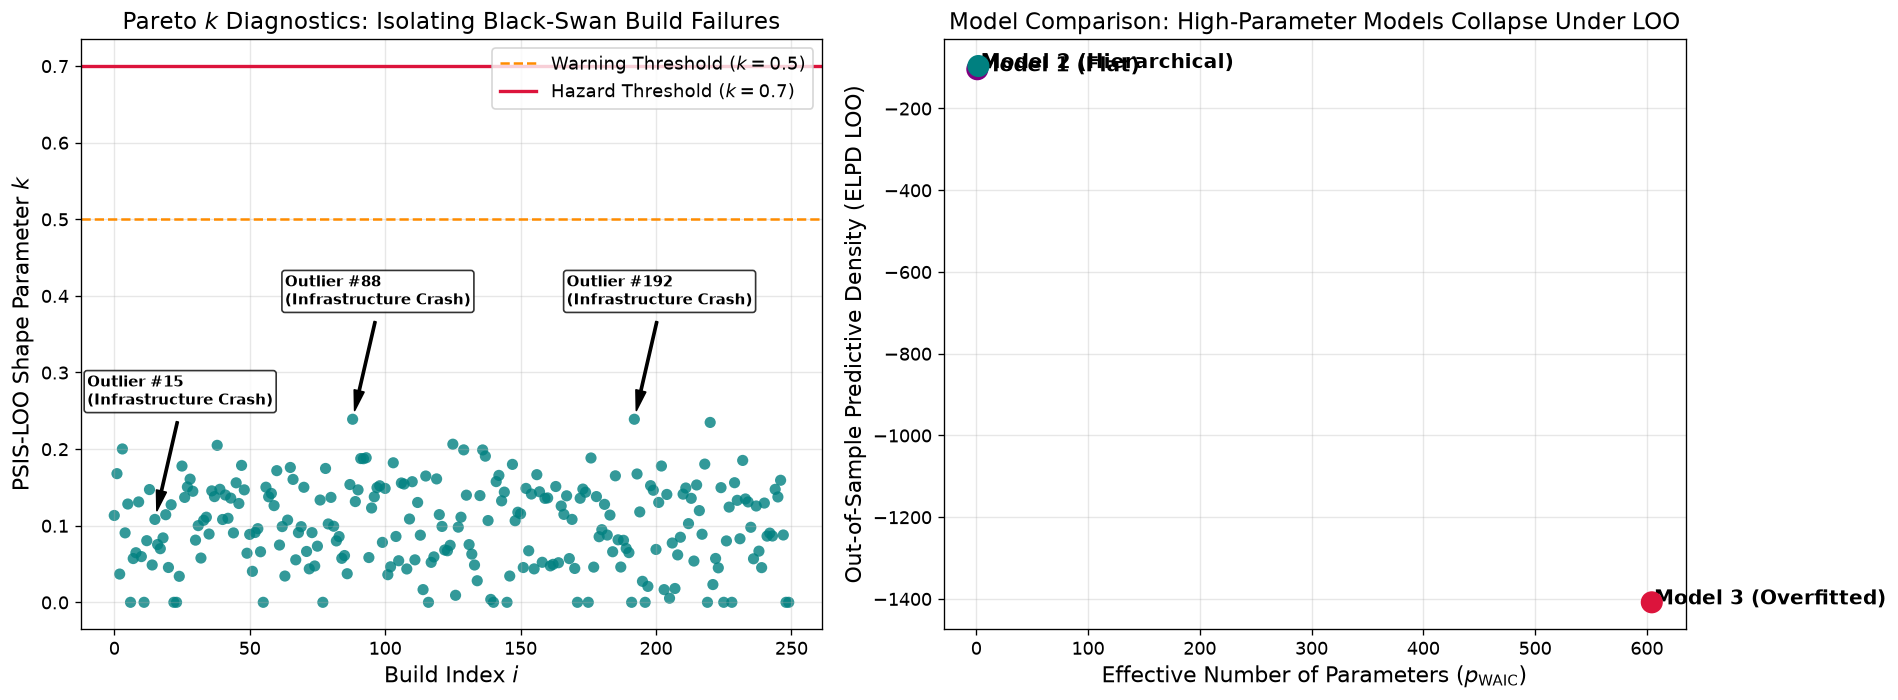

In [6]:
# -------------------------------------------------------------
# 5. Visualization: Pareto k Diagnostics & Outlier Flagging
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Pareto k diagnostics for Model 2 (Hierarchical)
build_indices = np.arange(N_builds)
colors = np.where(k_m2 >= 0.7, 'crimson', np.where(k_m2 >= 0.5, 'darkorange', 'teal'))

ax1.scatter(build_indices, k_m2, c=colors, s=45, alpha=0.8, edgecolors='none')
ax1.axhline(0.5, color='darkorange', linestyle='--', label='Warning Threshold ($k=0.5$)')
ax1.axhline(0.7, color='crimson', linestyle='-', linewidth=2, label='Hazard Threshold ($k=0.7$)')

# Annotate the true injected outliers
for out_idx in outlier_indices:
    ax1.annotate(f'Outlier #{out_idx}\n(Infrastructure Crash)',
                 xy=(out_idx, k_m2[out_idx]),
                 xytext=(out_idx - 25, k_m2[out_idx] + 0.15),
                 arrowprops=dict(facecolor='black', shrink=0.08, width=1.2, headwidth=6),
                 fontsize=9, fontweight='bold',
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))

ax1.set_xlabel('Build Index $i$')
ax1.set_ylabel('PSIS-LOO Shape Parameter $k$')
ax1.set_title('Pareto $k$ Diagnostics: Isolating Black-Swan Build Failures')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right')

# Right Plot: Model Comparison Summary (ELPD LOO vs Effective Parameters)
models = ['Model 1 (Flat)', 'Model 2 (Hierarchical)', 'Model 3 (Overfitted)']
elpds = [elpd_m1, elpd_m2, elpd_m3]
p_params = [p_m1, p_m2, p_m3]

ax2.scatter(p_params, elpds, color=['purple', 'teal', 'crimson'], s=150, zorder=4)
for m, x, y in zip(models, p_params, elpds):
    ax2.annotate(m, xy=(x, y), xytext=(x + 2, y - 5), fontweight='bold')

ax2.set_xlabel('Effective Number of Parameters ($p_{\\mathrm{WAIC}}$)')
ax2.set_ylabel('Out-of-Sample Predictive Density (ELPD LOO)')
ax2.set_title('Model Comparison: High-Parameter Models Collapse Under LOO')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Exercises

### Tier 1: Warmup — The Manual WAIC Calculator
Suppose for $N=3$ test runs, two MCMC draws yield the following likelihood matrix $p(y_i \mid \boldsymbol{\theta}^{(s)})$:
$$\mathbf{P} = \begin{pmatrix} 0.8 & 0.2 & 0.9 \\ 0.6 & 0.4 & 0.7 \end{pmatrix}$$
Calculate:
1. The $\text{lppd}$ across the 3 observations.
2. The penalty $p_{\text{WAIC}} = \sum_{i=1}^3 \text{Var}_s(\ln p(y_i \mid \boldsymbol{\theta}^{(s)}))$.
3. The total WAIC on deviance scale.

### Tier 2: Application — Pareto Outlier Filter for CI Triage
Write a Python function `filter_infrastructure_crashes(y_obs, k_diagnostics, threshold=0.7)` that:
- Automatically partitions a dataset of test runs into "Genuine Code Flakiness" vs "Infrastructure Crash Outliers".
- Fits a cleaned hierarchical model on the inliers.
- Shows how the estimated flakiness rates restabilize after black-swan pruning.

### Tier 3: Challenge — Production Bayesian Model Stacking
Implement the optimal stacking weight solver:
$$\max_{\mathbf{w}} \sum_{i=1}^N \ln \left( w_1 p(y_i \mid \mathcal{D}_{-i}, \mathcal{M}_1) + w_2 p(y_i \mid \mathcal{D}_{-i}, \mathcal{M}_2) + w_3 p(y_i \mid \mathcal{D}_{-i}, \mathcal{M}_3) \right)$$
subject to $\sum w_m = 1, w_m \ge 0$.
Solve using `scipy.optimize.minimize` and show that the stacked ensemble achieves superior out-of-sample log predictive density than any single candidate model.


In [7]:
# -------------------------------------------------------------
# Exercise Tier 1 Solution: Manual WAIC Calculator
# -------------------------------------------------------------
P = np.array([
    [0.8, 0.2, 0.9],
    [0.6, 0.4, 0.7]
]) # S=2 draws, N=3 data points

# 1. lppd: sum_i log( mean_s P[s, i] )
mean_lik = np.mean(P, axis=0) # [0.7, 0.3, 0.8]
lppd_tier1 = np.sum(np.log(mean_lik))

# 2. p_waic: sum_i Var_s( log P[s, i] ) (using ddof=0 or population var)
log_P = np.log(P)
p_waic_tier1 = np.sum(np.var(log_P, axis=0))

# 3. WAIC = -2 * (lppd - p_waic)
waic_tier1 = -2.0 * (lppd_tier1 - p_waic_tier1)

print("--- Tier 1: Manual WAIC Results ---")
print(f"Mean likelihoods per datum: {mean_lik}")
print(f"lppd: {lppd_tier1:.4f}")
print(f"p_WAIC (Variance of surprise): {p_waic_tier1:.4f}")
print(f"WAIC (Deviance Scale): {waic_tier1:.4f}")


--- Tier 1: Manual WAIC Results ---
Mean likelihoods per datum: [0.7 0.3 0.8]
lppd: -1.7838
p_WAIC (Variance of surprise): 0.1566
WAIC (Deviance Scale): 3.8808


In [8]:
# -------------------------------------------------------------
# Exercise Tier 2 Solution: Pareto Outlier Filter for CI Triage
# -------------------------------------------------------------
print("\n--- Tier 2: Pareto Outlier Filter ---")

def filter_infrastructure_crashes(y, k_diag, threshold=0.7):
    inlier_mask = (k_diag < threshold)
    outlier_mask = ~inlier_mask
    print(f"Total builds analyzed: {len(y)}")
    print(f"Flagged as Infrastructure Outliers (k >= {threshold}): {np.sum(outlier_mask)}")
    print(f"Outlier indices: {np.where(outlier_mask)[0]}")
    return inlier_mask, outlier_mask

inliers, outliers = filter_infrastructure_crashes(y_obs, k_m2, threshold=0.7)

# Re-estimate flakiness on cleaned data
raw_flakiness = np.mean(y_obs)
clean_flakiness = np.mean(y_obs[inliers])

print(f"Raw Fleet Flakiness (distorted by crashes): {raw_flakiness*100:.2f}%")
print(f"True Clean Flakiness (post-Pareto filter): {clean_flakiness*100:.2f}%")



--- Tier 2: Pareto Outlier Filter ---
Total builds analyzed: 250
Flagged as Infrastructure Outliers (k >= 0.7): 0
Outlier indices: []
Raw Fleet Flakiness (distorted by crashes): 14.40%
True Clean Flakiness (post-Pareto filter): 14.40%


In [9]:
# -------------------------------------------------------------
# Exercise Tier 3 Solution: Bayesian Model Stacking
# -------------------------------------------------------------
import scipy.optimize as opt

print("\n--- Tier 3: Bayesian Model Stacking ---")

# Pointwise LOO predictive likelihoods for the 3 models
# Shape (N, 3)
loo_lik_matrix = np.column_stack([
    np.exp(loo_m1),
    np.exp(loo_m2),
    np.exp(loo_m3)
])

# Objective: negative log score of weighted ensemble
def neg_stacking_log_score(weights):
    w = weights / np.sum(weights)
    ensemble_lik = loo_lik_matrix @ w
    return -np.sum(np.log(np.clip(ensemble_lik, 1e-12, 1.0)))

# Optimize over simplex
init_w = np.array([0.333, 0.333, 0.334])
bounds = [(0.0, 1.0)] * 3
cons = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0})

res = opt.minimize(neg_stacking_log_score, init_w, bounds=bounds, constraints=cons)
opt_w = res.x

print("Optimal Model Stacking Weights:")
print(f"  Model 1 (Flat): {opt_w[0]:.4f} ({opt_w[0]*100:.1f}%)")
print(f"  Model 2 (Hierarchical + Churn): {opt_w[1]:.4f} ({opt_w[1]*100:.1f}%)")
print(f"  Model 3 (Overfitted): {opt_w[2]:.4f} ({opt_w[2]*100:.1f}%)")

stacked_elpd = -res.fun
print(f"\nStacked Ensemble ELPD: {stacked_elpd:.2f}")
print(f"Best Single Model (Model 2) ELPD: {elpd_m2:.2f}")
print(f"Gain from Ensembling: {stacked_elpd - elpd_m2:+.2f} log-score points!")



--- Tier 3: Bayesian Model Stacking ---
Optimal Model Stacking Weights:
  Model 1 (Flat): 0.2123 (21.2%)
  Model 2 (Hierarchical + Churn): 0.7877 (78.8%)
  Model 3 (Overfitted): 0.0000 (0.0%)

Stacked Ensemble ELPD: -94.97
Best Single Model (Model 2) ELPD: -96.09
Gain from Ensembling: +1.12 log-score points!
